<a href="https://colab.research.google.com/github/Yagnasri161/MDS-CBP/blob/main/CBP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Diabetes Risk Analysis and Prediction Using Machine Learning


## Section 1: Setup & Import Libraries

In this section, we import all necessary libraries for data manipulation (`pandas`, `numpy`), visualization (`matplotlib`, `seaborn`), and machine learning (`sklearn`).

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-Learn Utilities
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# ML Models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

# Evaluation Metrics
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve
)

# Configure visualizations
%matplotlib inline
sns.set_theme(style="whitegrid")
print("Libraries successfully imported!")

Libraries successfully imported!


## Section 2: Download the Dataset

We will use `kagglehub` to download the public "Diabetes Health Indicators" dataset. We will then programmatically list the available files in the download directory.

In [ ]:
!pip install kagglehub -q

import kagglehub

# Download dataset
path = kagglehub.dataset_download("alexteboul/diabetes-health-indicators-dataset")
print("Dataset downloaded to:", path)

# List files inside the downloaded folder
files = os.listdir(path)
print("\nAvailable files:")
for f in files:
    print(f" - {f}")

Using Colab cache for faster access to the 'diabetes-health-indicators-dataset' dataset.
Dataset downloaded to: /kaggle/input/diabetes-health-indicators-dataset

Available files:
 - diabetes_binary_5050split_health_indicators_BRFSS2015.csv
 - diabetes_binary_health_indicators_BRFSS2015.csv
 - diabetes_012_health_indicators_BRFSS2015.csv


## Section 3: Load the Dataset & Exploratory Data Inspection


In [ ]:
# Identify target CSV
target_file = "diabetes_binary_health_indicators_BRFSS2015.csv"
full_path = os.path.join(path, target_file)

# Load dataset
df = pd.read_csv(full_path)

# Basic Info
print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns\n")
print("Column Names and Types:")
display(df.dtypes)

print("\nFirst 5 Rows:")
display(df.head())

# Missing values check
missing_values = df.isnull().sum().sum()
print(f"\nTotal Missing Values: {missing_values}")

# Duplicate check
duplicates_count = df.duplicated().sum()
print(f"Total Duplicate Rows: {duplicates_count}")

Dataset Shape: 253680 rows, 22 columns

Column Names and Types:


,0
Diabetes_binary,float64
HighBP,float64
HighChol,float64
CholCheck,float64
BMI,float64
Smoker,float64
Stroke,float64
HeartDiseaseorAttack,float64
PhysActivity,float64
Fruits,float64



First 5 Rows:


,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0



Total Missing Values: 0
Total Duplicate Rows: 24206


### Target Variable Explanation

* **`Diabetes_binary`**: Our target feature.
  * `0`: Represents no diabetes.
  * `1`: Represents reported pre-diabetes or diabetes.

### Data Cleaning Note
Although there are duplicate rows, this is a categorical/survey-based dataset (BRFSS 2015) where multiple respondents can realistically select identical answers to multiple-choice health indicators. Thus, we will keep them as valid responses rather than blindly deleting them to avoid removing valid representative profiles.

## Section 4: Exploratory Data Analysis (EDA)

Let's visualize target balance, age distribution, BMI distribution, correlation, and health metrics interaction.

/tmp/ipykernel_3466/3855348575.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(['No Diabetes (0)', 'Diabetes (1)'])


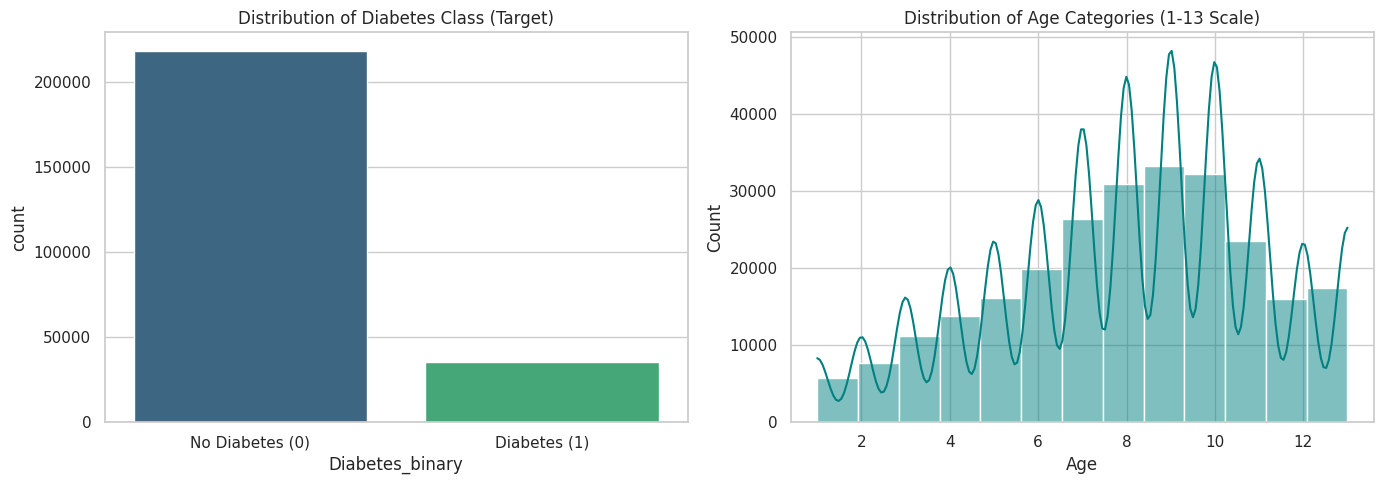

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Target Class Countplot
sns.countplot(data=df, x='Diabetes_binary', ax=axes[0], palette='viridis', hue='Diabetes_binary', legend=False)
axes[0].set_title('Distribution of Diabetes Class (Target)')
axes[0].set_xticklabels(['No Diabetes (0)', 'Diabetes (1)'])

# 2. Age Distribution
sns.histplot(data=df, x='Age', kde=True, bins=13, ax=axes[1], color='teal')
axes[1].set_title('Distribution of Age Categories (1-13 Scale)')

plt.tight_layout()
plt.show()

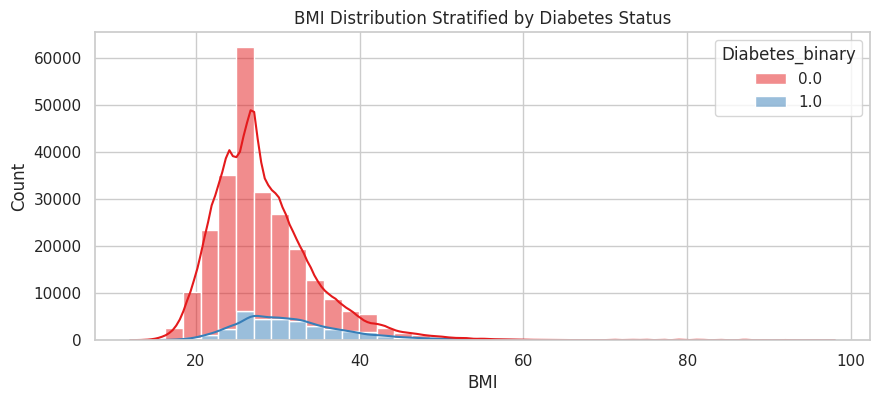

In [ ]:
plt.figure(figsize=(10, 4))
sns.histplot(data=df, x='BMI', kde=True, hue='Diabetes_binary', bins=40, palette='Set1', multiple='stack')
plt.title('BMI Distribution Stratified by Diabetes Status')
plt.xlabel('BMI')
plt.ylabel('Count')
plt.show()

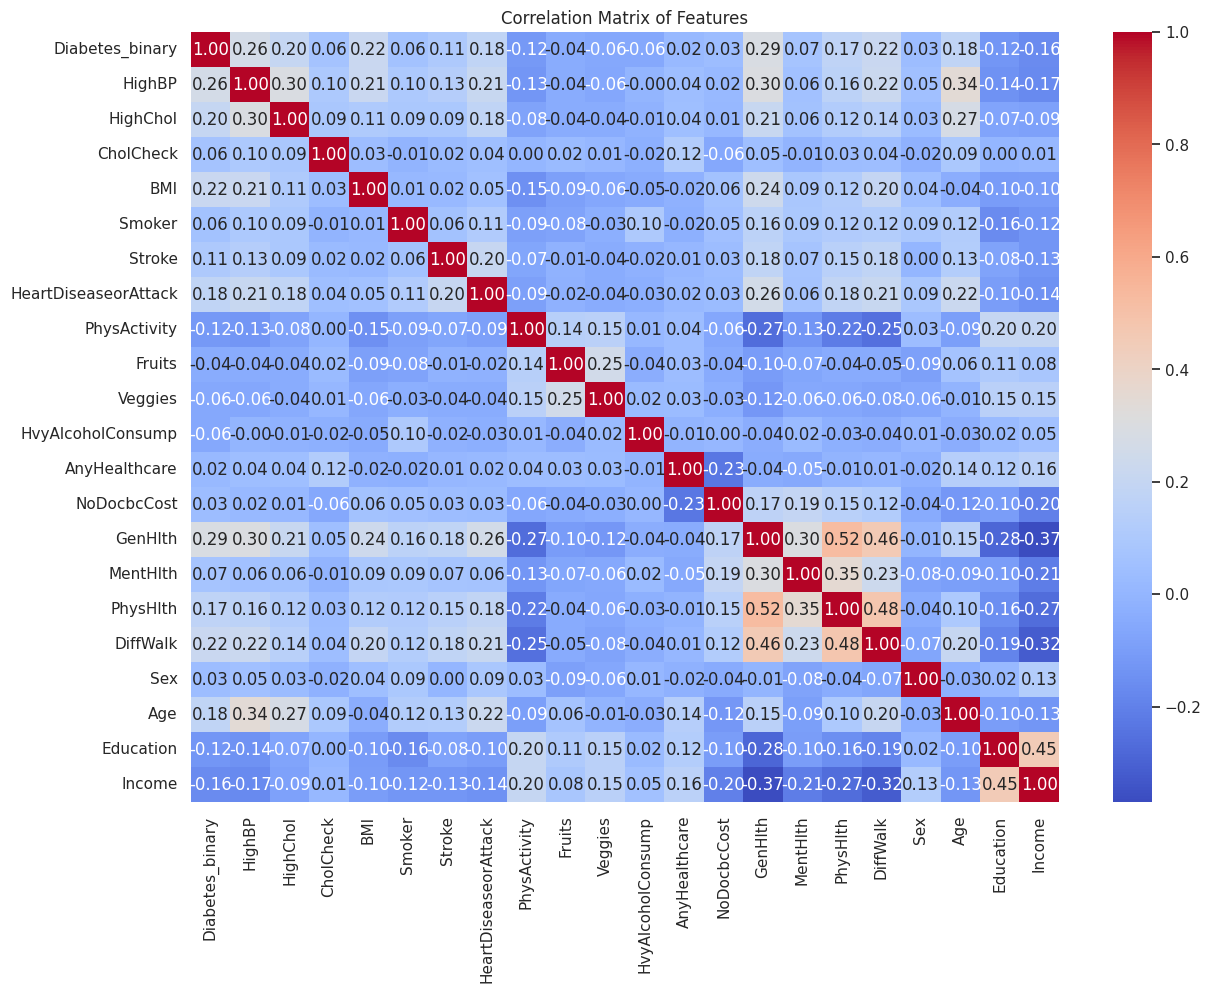

In [ ]:
# Calculate and plot correlations with Target
plt.figure(figsize=(14, 10))
corr_matrix = df.corr()
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", cbar=True)
plt.title("Correlation Matrix of Features")
plt.show()

/tmp/ipykernel_3466/1769274151.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(['No Diabetes (0)', 'Diabetes (1)'])
/tmp/ipykernel_3466/1769274151.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(['No Diabetes (0)', 'Diabetes (1)'])


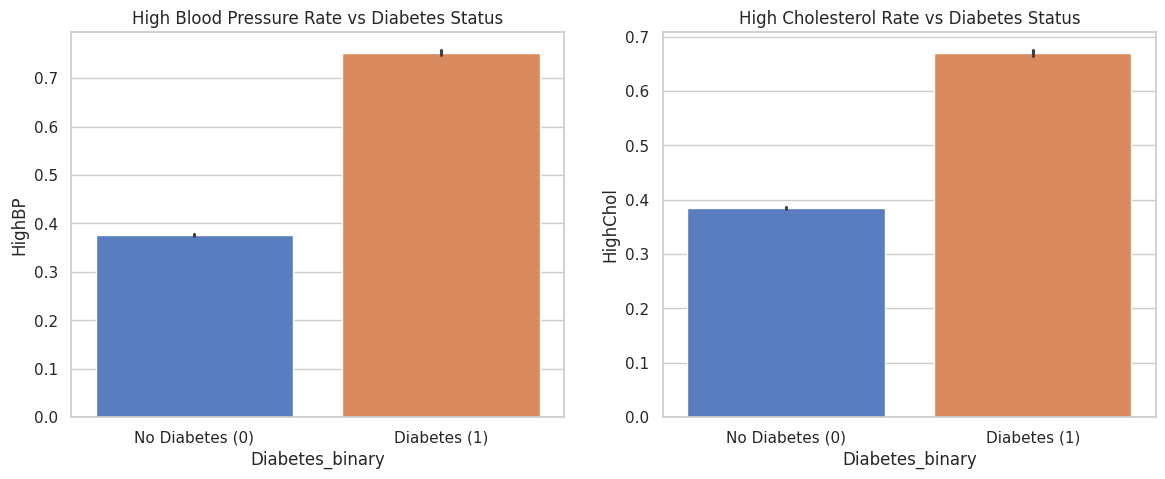

In [ ]:
# Highlight relationship with key risk indicators
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=df, x='Diabetes_binary', y='HighBP', ax=axes[0], palette='muted', hue='Diabetes_binary', legend=False)
axes[0].set_title('High Blood Pressure Rate vs Diabetes Status')
axes[0].set_xticklabels(['No Diabetes (0)', 'Diabetes (1)'])

sns.barplot(data=df, x='Diabetes_binary', y='HighChol', ax=axes[1], palette='muted', hue='Diabetes_binary', legend=False)
axes[1].set_title('High Cholesterol Rate vs Diabetes Status')
axes[1].set_xticklabels(['No Diabetes (0)', 'Diabetes (1)'])

plt.show()

## Section 5: Data Preparation & Stratified Split

To ensure responsive executions during lab tests and viva demos while maintaining data integrity, we will take a computationally practical stratified sample of **30,000 samples** for model evaluation and split it into stratified Train and Test sets.

In [ ]:
# Define Features and Target
X = df.drop(columns=['Diabetes_binary'])
y = df['Diabetes_binary']

# Create a computationally practical stratified sample
SAMPLE_SIZE = 30000
_, X_sample, _, y_sample = train_test_split(
    X, y, test_size=SAMPLE_SIZE, stratify=y, random_state=42
)

# Perform a Stratified Train-Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X_sample, y_sample, test_size=0.2, stratify=y_sample, random_state=42
)

print(f"Modeling Sample Size: {SAMPLE_SIZE}")
print(f"Training Set: {X_train.shape[0]} samples")
print(f"Testing Set: {X_test.shape[0]} samples")

Modeling Sample Size: 30000
Training Set: 24000 samples
Testing Set: 6000 samples


## Section 6: Model Training & Comparison

We will define 4 pipelines utilizing `StandardScaler` to prevent data leakage and train the models:
1. Logistic Regression
2. Decision Tree
3. Random Forest
4. K-Nearest Neighbors

In [ ]:
# Initialize model pipelines
models = {
    'Logistic Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('classifier', LogisticRegression(random_state=42, max_iter=1000))
    ]),
    'Decision Tree': Pipeline([
        ('scaler', StandardScaler()),
        ('classifier', DecisionTreeClassifier(random_state=42, max_depth=8))
    ]),
    'Random Forest': Pipeline([
        ('scaler', StandardScaler()),
        ('classifier', RandomForestClassifier(random_state=42, n_estimators=100, max_depth=10, n_jobs=-1))
    ]),
    'K-Nearest Neighbors': Pipeline([
        ('scaler', StandardScaler()),
        ('classifier', KNeighborsClassifier(n_neighbors=15))
    ])
}

# Train all models
for name, pipeline in models.items():
    pipeline.fit(X_train, y_train)
    print(f"Finished training {name}.")

Finished training Logistic Regression.
Finished training Decision Tree.
Finished training Random Forest.
Finished training K-Nearest Neighbors.


## Section 7: Model Evaluation

We evaluate the positive class `1` (Diabetes risk detected). We analyze: Accuracy, Precision, Recall, F1-Score, and ROC-AUC.

### Why accuracy alone is misleading:
Accuracy can be misleading when class distributions are imbalanced. For example, if 85% of survey respondents are healthy, a dummy model predicting 'No Diabetes' for every single patient would yield 85% accuracy but discover exactly 0% of active risks.

In [ ]:
results = {}

for name, pipeline in models.items():
    # Predictions
    y_pred = pipeline.predict(X_test)
    y_proba = pipeline.predict_proba(X_test)[:, 1]

    # Calculate metrics
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_proba)

    results[name] = {
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1,
        'ROC-AUC': auc,
        'y_pred': y_pred,
        'y_proba': y_proba
    }

# Create a tidy table summary
summary_df = pd.DataFrame(results).T.drop(columns=['y_pred', 'y_proba'])
display(summary_df.round(4))

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Logistic Regression,0.8635,0.538813,0.141148,0.223697,0.835362
Decision Tree,0.859,0.480315,0.145933,0.223853,0.796378
Random Forest,0.861667,0.538462,0.050239,0.091904,0.830739
K-Nearest Neighbors,0.8585,0.463687,0.099282,0.163547,0.776126


### Plotting Confusion Matrices and ROC Curves

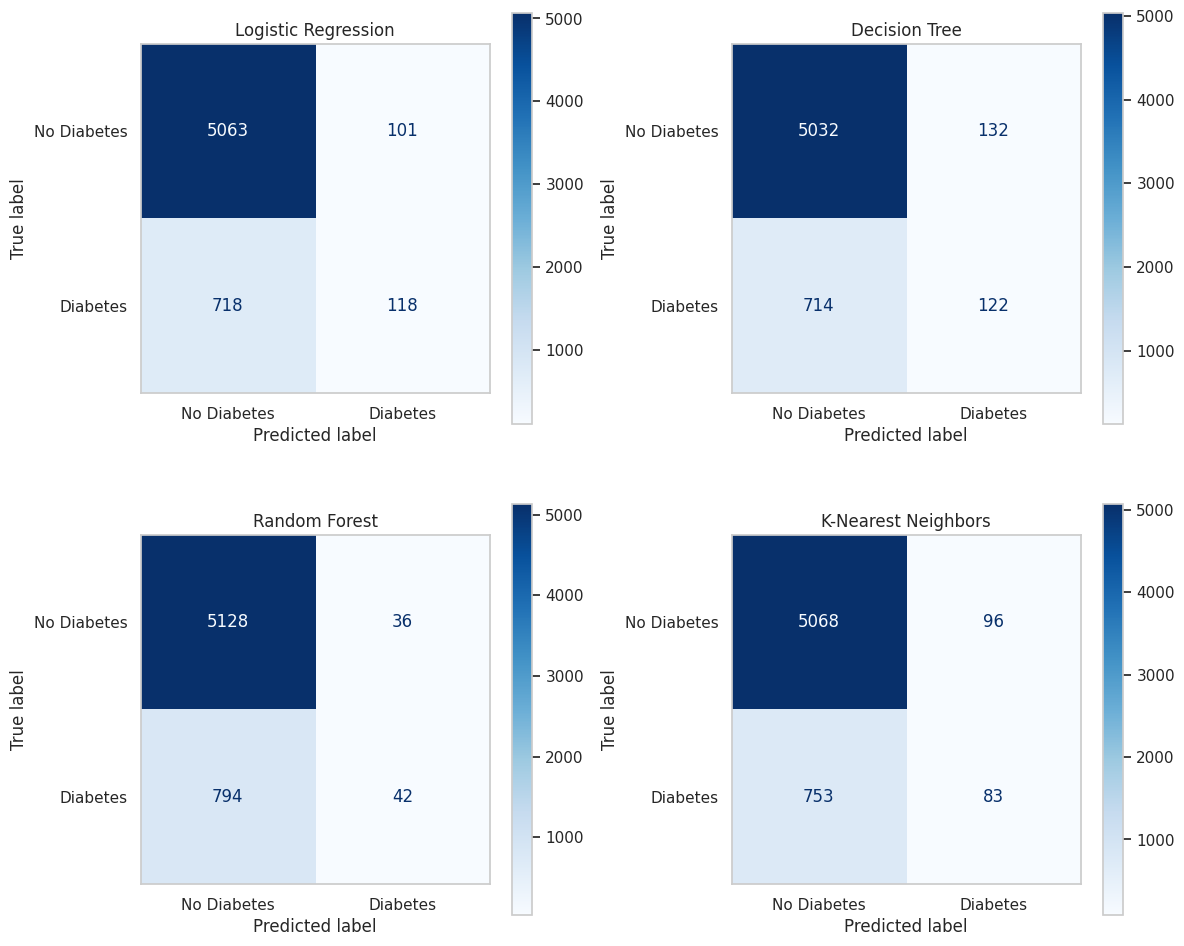

In [ ]:
# 1. Confusion Matrices
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.ravel()

for i, (name, metrics) in enumerate(results.items()):
    cm = confusion_matrix(y_test, metrics['y_pred'])
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Diabetes', 'Diabetes'])
    disp.plot(ax=axes[i], cmap='Blues', values_format='d')
    axes[i].set_title(name)
    axes[i].grid(False)

plt.tight_layout()
plt.show()

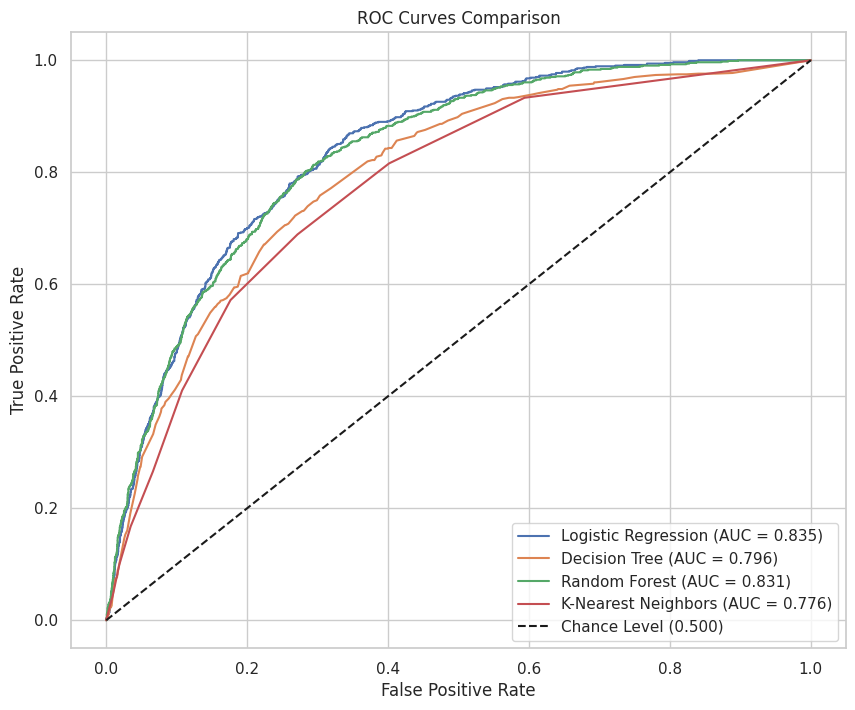

In [ ]:
# 2. ROC Curve Plot
plt.figure(figsize=(10, 8))
for name, metrics in results.items():
    fpr, tpr, _ = roc_curve(y_test, metrics['y_proba'])
    plt.plot(fpr, tpr, label=f"{name} (AUC = {metrics['ROC-AUC']:.3f})")

plt.plot([0, 1], [0, 1], 'k--', label='Chance Level (0.500)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves Comparison')
plt.legend()
plt.show()

## Section 8: Feature Importance (Random Forest)

Let's extract and plot the feature importances from the trained Random Forest classifier. Note that these importances show statistical correlation/predictive power but **do not imply direct physical causation**.

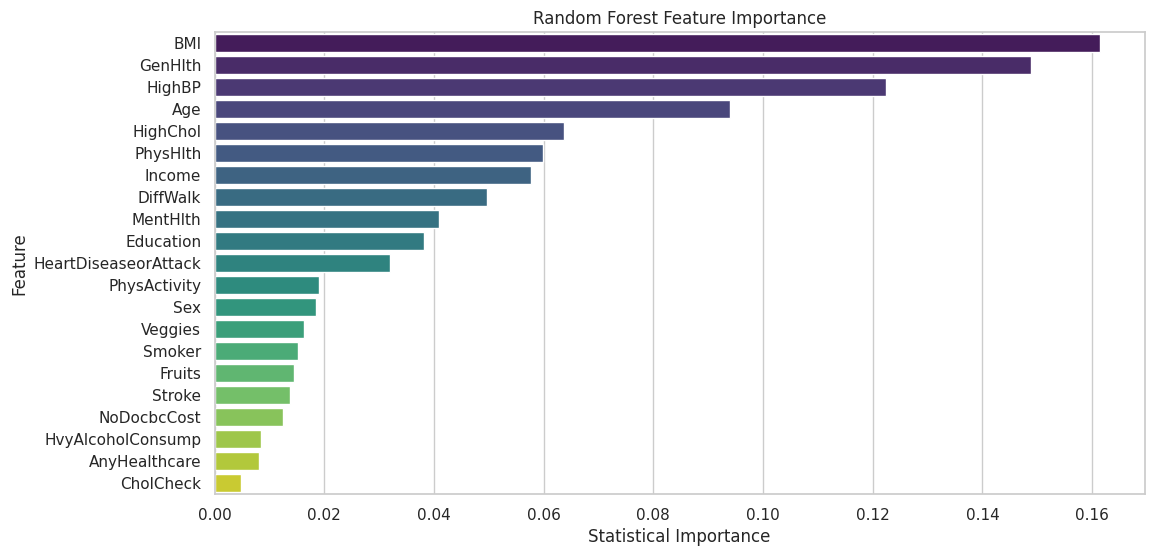

In [ ]:
rf_model = models['Random Forest'].named_steps['classifier']
importances = rf_model.feature_importances_
features = X.columns

# Create DataFrame
feat_df = pd.DataFrame({'Feature': features, 'Importance': importances})
feat_df = feat_df.sort_values(by='Importance', ascending=False)

# Plot
plt.figure(figsize=(12, 6))
sns.barplot(data=feat_df, x='Importance', y='Feature', palette='viridis', hue='Feature', legend=False)
plt.title('Random Forest Feature Importance')
plt.xlabel('Statistical Importance')
plt.ylabel('Feature')
plt.show()

## Section 9: Custom Prediction Function

We provide a reusable, interactive helper function designed to accept raw input values, align them in the correct feature order, scale them inside the pipeline, and output prediction probabilities and classifications.

In [ ]:
def predict_diabetes_risk(user_inputs, model_name='Random Forest'):
    """
    Accepts a dictionary of user input indicators matched to column names,
    estimates risk classification, and outputs probabilities.
    """
    # Build a 1-row DataFrame mimicking the features pattern
    input_df = pd.DataFrame([user_inputs])

    # Reorder columns to match fit layout exactly
    input_df = input_df[X.columns]

    # Select Pipeline
    pipeline = models[model_name]

    # Predict
    prob = pipeline.predict_proba(input_df)[0][1]
    prediction = pipeline.predict(input_df)[0]

    result_label = "High Risk of Diabetes (1)" if prediction == 1 else "Low Risk of Diabetes (0)"

    print(f"\n--- Prediction using {model_name} ---")
    print(f"Estimated Probability: {prob * 100:.2f}%")
    print(f"Classification Decision: {result_label}")

# --- Simplified Dynamic User Input Block for Colab ---
print("Please enter the following key health metrics for diabetes prediction:")
try:
    # Only ask for key physical, medical, and lifestyle markers
    high_bp = float(input("High Blood Pressure (1.0 for Yes, 0.0 for No): ") or 0.0)
    high_chol = float(input("High Cholesterol (1.0 for Yes, 0.0 for No): ") or 0.0)
    chol_check = float(input("Cholesterol Check in past 5 years (1.0 for Yes, 0.0 for No): ") or 1.0)
    bmi = float(input("BMI (e.g., 28.5): ") or 25.0)
    smoker = float(input("Smoker (Have smoked at least 100 cigarettes) (1.0 for Yes, 0.0 for No): ") or 0.0)
    stroke = float(input("Ever had a stroke? (1.0 for Yes, 0.0 for No): ") or 0.0)
    heart_dis = float(input("Heart Disease or Attack history (1.0 for Yes, 0.0 for No): ") or 0.0)
    phys_act = float(input("Physical Activity in past 30 days (1.0 for Yes, 0.0 for No): ") or 1.0)
    fruits = float(input("Consume Fruit 1+ times per day (1.0 for Yes, 0.0 for No): ") or 1.0)
    veggies = float(input("Consume Vegetables 1+ times per day (1.0 for Yes, 0.0 for No): ") or 1.0)
    heavy_alc = float(input("Heavy Alcohol Consumption (1.0 for Yes, 0.0 for No): ") or 0.0)
    gen_health = float(input("General Health self-rating (Scale 1-5: 1=Excellent, 5=Poor): ") or 3.0)
    ment_health = float(input("Days of poor mental health past 30 days (0-30): ") or 0.0)
    phys_health = float(input("Days of poor physical health past 30 days (0-30): ") or 0.0)
    diff_walk = float(input("Serious difficulty walking or climbing stairs (1.0 for Yes, 0.0 for No): ") or 0.0)
    sex = float(input("Sex (1.0 for Male, 0.0 for Female): ") or 1.0)
    age = float(input("Age Category (Scale 1-13: e.g., 9 for age 60-64): ") or 9.0)

    # Auto-fill background/socio-economic features with typical default/median values to maintain schema
    healthcare = 1.0
    no_doc_cost = 0.0
    education = 5.0
    income = 6.0

    # Package inputs
    dynamic_user = {
        'HighBP': high_bp, 'HighChol': high_chol, 'CholCheck': chol_check, 'BMI': bmi,
        'Smoker': smoker, 'Stroke': stroke, 'HeartDiseaseorAttack': heart_dis, 'PhysActivity': phys_act,
        'Fruits': fruits, 'Veggies': veggies, 'HvyAlcoholConsump': heavy_alc, 'AnyHealthcare': healthcare,
        'NoDocbcCost': no_doc_cost, 'GenHlth': gen_health, 'MentHlth': ment_health, 'PhysHlth': phys_health,
        'DiffWalk': diff_walk, 'Sex': sex, 'Age': age, 'Education': education, 'Income': income
    }

    # Run prediction using the random forest pipeline
    predict_diabetes_risk(dynamic_user, model_name='Random Forest')
except ValueError as e:
    print(f"\nInvalid input entered: {e}. Please enter numeric values.")

Please enter the following key health metrics for diabetes prediction:
